# Counts, quality, September gap and Smart

Smart is a retrospective policy reconstruction with a September-trained final model and residual expiry-value scenario. Read FINDINGS.md for execution and selection limitations.

In [1]:
from pathlib import Path
import pandas as pd,json,gzip,numpy as np
import matplotlib.pyplot as plt
ROOT=Path('/Users/ramachandran/MACD-mini-ADV/research/september_supertrend_pivots_20261003/followup')
q=pd.read_csv(ROOT/'actual_trade_quality.csv')
s=pd.read_csv(ROOT/'smart_comparisons.csv')
g=pd.read_csv(ROOT/'old_gap_inventory.csv')
rules=['baseline', 'premium_st', 'spot_st', 'pivot_room', 'both_st_room']
q[(q.cohort=='old_active')&q.rule.isin(rules)]

,cohort,rule,new_episodes,closed_new_episodes,open_new_episodes,new_buy_fills,new_sell_fills,closed_win_rate_pct,closed_profit_factor,closed_mean_return_pct,closed_median_return_pct,closed_mean_pnl_rupees,closed_mean_win_rupees,closed_mean_loss_rupees,closed_total_pnl_rupees,open_marked_pnl_rupees,all_new_marked_pnl_rupees,carry_in_pnl_rupees,closed_count_CE,closed_count_PE
13,old_active,baseline,621,544,77,1127,1188,40.441176,1.140172,-2.770404,-7.295063,1433.140765,28825.331819,-17166.495136,7.796286e+05,1.138534e+06,1.918162e+06,766494.1235,265,279
15,old_active,premium_st,395,346,49,715,780,42.774566,1.340815,-0.976456,-6.645796,3267.859359,30055.776241,-16755.432048,1.130679e+06,7.238490e+05,1.854528e+06,910615.8960,187,159
16,old_active,spot_st,443,383,60,770,827,40.469974,1.194655,-1.776873,-7.250370,1957.914130,29691.820588,-16896.276664,7.498811e+05,6.644724e+05,1.414354e+06,910615.8960,206,177
20,old_active,pivot_room,462,402,60,839,875,39.054726,1.135042,-2.900491,-7.295063,1374.183475,29574.256303,-16696.883602,5.524218e+05,9.888793e+05,1.541301e+06,825620.2560,194,208
22,old_active,both_st_room,265,231,34,457,508,41.558442,1.432943,0.239846,-6.593703,4010.320223,31938.748939,-15849.895752,9.263840e+05,3.346336e+05,1.261018e+06,910615.8960,128,103


In [2]:
g[g.rule.isin(rules)]

,begin,end,rule,marked_pnl,new_trades,recorded_fills,modelled_exit_fills,opening_positions,closing_positions
0,2026-09-18,2026-09-29,baseline,-1.323698e+06,96,284,0,62,81
1,2026-09-19,2026-09-29,baseline,-1.732402e+06,0,0,0,81,81
2,2026-09-18,2026-09-29,premium_st,-1.485443e+06,61,199,0,45,53
3,2026-09-19,2026-09-29,premium_st,-1.874463e+06,0,0,0,53,53
4,2026-09-18,2026-09-29,spot_st,-1.886727e+06,77,208,0,40,64
5,2026-09-19,2026-09-29,spot_st,-2.289223e+06,0,0,0,64,64
12,2026-09-18,2026-09-29,pivot_room,-1.262754e+06,76,224,0,50,64
13,2026-09-19,2026-09-29,pivot_room,-1.509971e+06,0,0,0,64,64
16,2026-09-18,2026-09-29,both_st_room,-1.327868e+06,46,140,0,30,38
17,2026-09-19,2026-09-29,both_st_room,-1.503184e+06,0,0,0,38,38


In [3]:
s[(s.extra_bps==0)&s.rule.isin(rules)&s.cohort.isin(['period_18_29','period_19_29','full_sep'])][['capital','cohort','rule','new_trades','closed_new_trades','closed_win_rate_pct','closed_profit_factor','marked_pnl','delta_pnl','expired_residuals']]

,capital,cohort,rule,new_trades,closed_new_trades,closed_win_rate_pct,closed_profit_factor,marked_pnl,delta_pnl,expired_residuals
0,100000,full_sep,baseline,284,269,48.698885,1.278564,5.633642e+05,0.000000e+00,7
2,100000,period_18_29,baseline,191,177,44.067797,1.050929,9.910747e+04,0.000000e+00,0
3,100000,period_19_29,baseline,177,163,42.944785,0.999417,9.056526e+04,0.000000e+00,0
5,100000,full_sep,premium_st,241,228,49.122807,1.312563,3.466192e+05,-2.167450e+05,5
7,100000,period_18_29,premium_st,154,144,45.138889,1.046953,1.146964e+05,1.558890e+04,0
8,100000,period_19_29,premium_st,142,132,44.696970,1.022052,8.154038e+04,-9.024881e+03,0
10,100000,full_sep,spot_st,270,255,46.666667,1.261829,4.147527e+05,-1.486115e+05,5
12,100000,period_18_29,spot_st,177,168,41.071429,0.931824,4.422708e+04,-5.488040e+04,1
13,100000,period_19_29,spot_st,162,153,41.176471,0.914898,2.017691e+04,-7.038836e+04,1
30,100000,full_sep,pivot_room,252,239,46.025105,1.248225,2.817246e+05,-2.816396e+05,6


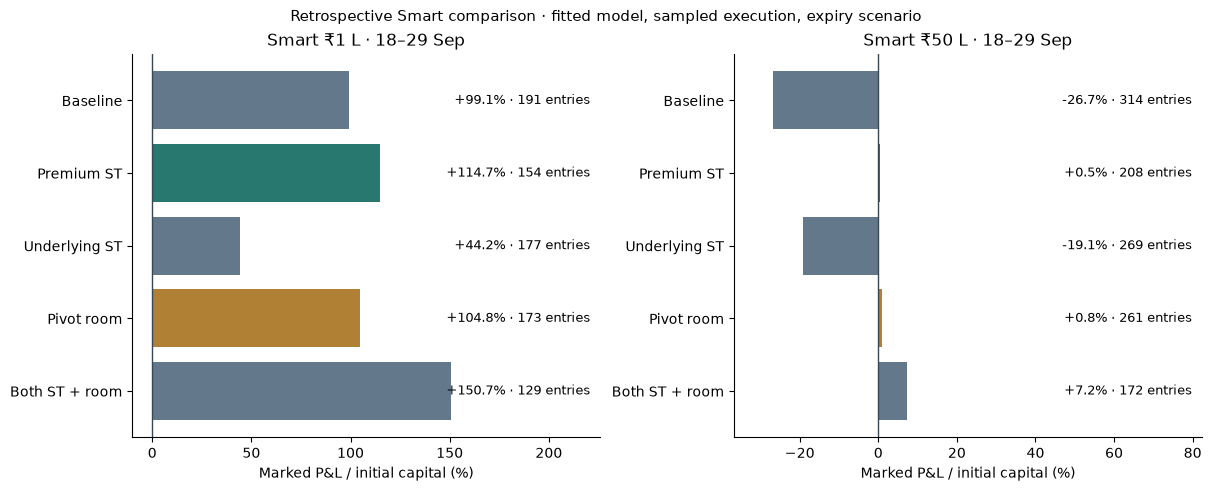

In [4]:
fig,axes=plt.subplots(1,2,figsize=(12,4.8),layout='constrained')
labels=['Baseline','Premium ST','Underlying ST','Pivot room','Both ST + room']
for ax,cap in zip(axes,[100000,5000000]):
    block=s[(s.capital==cap)&(s.extra_bps==0)&(s.cohort=='period_18_29')].set_index('rule').loc[rules]
    values=100*block.marked_pnl.to_numpy()/cap
    ax.barh(labels,values,color=['#64788b','#28786f','#64788b','#b08135','#64788b'])
    ax.invert_yaxis();ax.axvline(0,color='#384754',lw=1);ax.set_xlabel('Marked P&L / initial capital (%)');ax.set_title(f'Smart ₹{cap/100000:g} L · 18–29 Sep')
    for i,(value,n) in enumerate(zip(values,block.new_trades)):ax.text(.98,i,f'{value:+.1f}% · {int(n)} entries',transform=ax.get_yaxis_transform(),ha='right',va='center',fontsize=9)
    ax.set_xlim(min(min(values),0)-10,max(max(values),0)+75);ax.spines[['top','right']].set_visible(False)
fig.suptitle('Retrospective Smart comparison · fitted model, sampled execution, expiry scenario',fontsize=11)
fig.savefig(ROOT/'smart_18_29.png',dpi=150,bbox_inches='tight');plt.show()

In [5]:
validation=json.loads((ROOT/'smart_validation.json').read_text())
assert validation['unit_checks_passed']==10
assert all(b['cash_nonnegative'] and b['no_unpriced_daily_positions'] for b in validation['books'].values())
{'tested_books':len(validation['books']),'unit_checks':10,'out_of_sample':validation['out_of_sample'],'broker_order_calls':validation['broker_order_calls']}

{'tested_books': 34,
 'unit_checks': 10,
 'out_of_sample': False,
 'broker_order_calls': 0}

No promotion follows from this reconstruction. Entries are position episodes, not the number of partial-exit fills. Old carried inventory, current actual-entry schedules and retrospective Smart books remain separate.